# Projeto de Deep Learning — 03. Formulação multiclasse e baseline (regressão logística)

**Tarefa (enunciado):** estimar a probabilidade de uma empresa falir dentro de um horizonte de tempo especificado.

## Formulação

Cada arquivo da base (`1year` … `5year`) traz balanços tirados a uma distância fixa do desfecho: o arquivo `kyear`
tem balanços de **6 − k anos antes**. Empilhamos os cinco arquivos e definimos um alvo **multiclasse**:

| classe | significado | origem |
|---|---|---|
| 0 | não faliu | `class = 0` em qualquer arquivo |
| 1 | faliu no 1º ano depois do balanço | `class = 1` em `5year` |
| 2 | faliu no 2º ano depois | `class = 1` em `4year` |
| 3 | faliu no 3º ano depois | `class = 1` em `3year` |
| 4 | faliu no 4º ano depois | `class = 1` em `2year` |
| 5 | faliu no 5º ano depois | `class = 1` em `1year` |

O modelo devolve $P(y = h \mid \text{indicadores})$ para $h = 0, \dots, 5$. **Interpretação: $P(y = h)$ é a
probabilidade de a empresa falir no ano $h$ depois do balanço (ano exato).** A probabilidade de falir em algum dos
cinco anos é $1 - P(y = 0)$.

**Suposição.** As empresas ativas entram como "não falha em nenhum horizonte", mas só se sabe que não faliram dentro do
período observado. É uma censura que o multiclasse ignora; fica registrada como limitação.

**Vazamento.** O arquivo de origem **não entra como variável**: para as falidas ele determina a classe. Ele só é usado
para estratificar. Todo pré-processamento (quantis, winsorização, imputação, seleção, PCA, SMOTE) é ajustado
**apenas nos dados de treino de cada etapa**.

## Protocolo

- **Treino 80% / teste 20%**, estratificado pela classe multiclasse. O teste é usado uma única vez, no fim.
- **Validação cruzada estratificada de 5 folds** dentro do treino para todas as escolhas (pré-processamento e hiperparâmetros).
- **Métricas** (enunciado): para cada ano $h = 1, \dots, 5$, a classe $h$ contra o resto: PR-AUC, ROC-AUC e recall a
  5% de falsos positivos. **Critério de escolha: PR-AUC média nos 5 anos.** Também: log loss e Brier multiclasse.
- **Entradas:** os 63 indicadores originais (X37 descartado por ter ~44% de faltantes). Os faltantes restantes são
  imputados pela **mediana do treino**; nenhuma variável nova é criada.
- **Redução de dimensão obrigatória**, com cortes fixos: filtro de Pearson (|r| > 0,8) + VIF (< 5), ou PCA com 95% da
  variância. A validação cruzada escolhe entre os dois.
- Quando o treino usa pesos de classe, oversampling ou SMOTE, o modelo aprende como se as classes fossem igualmente
  frequentes. As probabilidades são **corrigidas de volta para as frequências reais** (correção de *priors*,
  Saerens et al., 2002): $p_k \propto \hat p_k \cdot \pi_k / (1/6)$.

## Experimentos deste notebook

**Regressão logística multinomial regularizada** (*baseline* do enunciado): fatorial completo de pré-processamento
(4 escalas × 2 reduções × 4 tratamentos de desbalanceamento = 32 combinações), depois busca de hiperparâmetros e, por fim, uma **seleção robusta**: os 3 melhores candidatos são reavaliados numa CV repetida (3 × 5 folds) com testes pareados (t corrigido de Nadeau-Bengio e *bootstrap* por empresa, correção de Holm).

## Funções do projeto

As mesmas funções aparecem no início dos notebooks 03 a 06, para cada um rodar sozinho.

**Dados, pré-processamento e métricas.** Funções compartilhadas pelos notebooks 03, 04 e 05 (formulação multiclasse). Alvo multiclasse ---------------- Cada linha da base é um balanço. O arquivo `kyear.arff` traz balanços tirados (6 - k) anos antes do desfecho.   y = 0        se a empresa não faliu no período observado   y = h ∈ {1,…,5}   se a empresa faliu h anos depois daquele balanço (h = 6 - k) Interpretação: P(y = h) é a probabilidade de a empresa falir no ano h depois do balanço (ano exato). Cada ano é avaliado como um problema "um contra o resto". A pergunta "faliu em algum dos 5 anos?" usa 1 - P(y = 0). Pré-processamento: só os 63 indicadores originais (X37 descartado, ~44% de faltantes); faltantes imputados pela mediana do treino; nenhuma variável nova é criada. A redução de dimensão é obrigatória: filtro de correlação + VIF ou PCA, com cortes fixos. Suposição (limitação): as empresas ativas são tratadas como "não falha em nenhum horizonte", embora só se saiba que não faliram dentro do período observado (censura). O arquivo de origem NÃO entra como variável: para as falidas ele determina a classe (vazamento).

In [1]:
from pathlib import Path
import json
import os
import zipfile
import warnings

os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count()))
warnings.filterwarnings('ignore', message='.*physical cores.*')

import numpy as np
import pandas as pd
from scipy.io import arff

from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import QuantileTransformer, RobustScaler, StandardScaler

set_config(transform_output='pandas')

RAPIDO = os.environ.get('RAPIDO') == '1'  # teste rápido do código (poucas configurações, poucas épocas)
SEMENTE = 42
N_FOLDS = 2 if RAPIDO else 5
REPETICOES = 2 if RAPIDO else 3   # repetições da CV (com outras divisões) na seleção robusta e nos testes
URL_DADOS = 'https://archive.ics.uci.edu/static/public/365/polish+companies+bankruptcy+data.zip'
FPR_ALVO = 0.05
CLASSES = [0, 1, 2, 3, 4, 5]
HORIZONTES = [1, 2, 3, 4, 5]
NOME_CLASSE = {0: 'não faliu', 1: 'faliu no ano 1', 2: 'faliu no ano 2', 3: 'faliu no ano 3',
               4: 'faliu no ano 4', 5: 'faliu no ano 5'}
VARS = [f'X{i}' for i in range(1, 65) if i != 37]  # X37 tem ~44% de faltantes (notebook 02)

ESCALAS = ['padronização', 'robusta', 'winsor + padronização', 'quantis (normal)']
SELECOES = ['corr + VIF', 'PCA 95%']  # redução obrigatória, cortes fixos (|r| > 0,8 e VIF ≥ 5; 95% da variância)
BALANCOS = ['nenhum', 'pesos', 'oversampling', 'SMOTE']

# Estilo dos gráficos (o mesmo dos notebooks anteriores)
TINTA, TINTA2, MUDO, GRADE, EIXO = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
ESTILO = {
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': EIXO, 'axes.labelcolor': TINTA2, 'axes.titlecolor': TINTA, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': MUDO, 'ytick.color': MUDO, 'text.color': TINTA2, 'legend.frameon': False,
    'figure.dpi': 110, 'lines.linewidth': 2, 'font.size': 10,
}
COR = {'Regressão logística': '#2a78d6', 'MLP': '#eb6834'}
COR_H = dict(zip(HORIZONTES, ['#104281', '#1c5cab', '#2a78d6', '#5598e7', '#86b6ef']))


# ----------------------------------------------------------------------------------------------------------------
# Dados
# ----------------------------------------------------------------------------------------------------------------
def carregar(pasta='dados'):
    pasta = Path(pasta)
    arquivos = {k: pasta / f'{k}year.arff' for k in range(1, 6)}
    if not all(p.exists() for p in arquivos.values()):
        zip_ = pasta / 'polish+companies+bankruptcy+data.zip'
        if not zip_.exists():  # baixa da UCI na primeira execução
            import urllib.request
            pasta.mkdir(parents=True, exist_ok=True)
            urllib.request.urlretrieve(URL_DADOS, zip_)
        with zipfile.ZipFile(zip_) as z:
            z.extractall(pasta)
    partes = []
    for k, p in arquivos.items():
        registros, _ = arff.loadarff(p)
        d = pd.DataFrame(registros)
        d.columns = [c.replace('Attr', 'X') for c in d.columns]
        d['class'] = d['class'].str.decode('utf-8').astype(int)
        partes.append(d.drop_duplicates().assign(arquivo=k))
    df = pd.concat(partes, ignore_index=True)
    df[VARS] = df[VARS].replace([np.inf, -np.inf], np.nan)
    df['y'] = np.where(df['class'] == 1, 6 - df['arquivo'], 0).astype(int)
    return df


def dividir(df, frac_teste=0.20):
    """Treino/teste estratificado pela classe multiclasse (que já inclui o horizonte das falidas)."""
    tr, te = train_test_split(df, test_size=frac_teste, stratify=df['y'], random_state=SEMENTE)
    return tr.reset_index(drop=True), te.reset_index(drop=True)


def folds(y, n=5, repeticao=0):
    """Folds estratificados da CV. repeticao = 0 é a divisão usada em todas as escolhas; repetições 1, 2, … sorteiam
    outras divisões (CV repetida), usadas só na seleção robusta e nos testes estatísticos."""
    return list(StratifiedKFold(n, shuffle=True, random_state=SEMENTE + repeticao).split(np.zeros(len(y)), y))


# ----------------------------------------------------------------------------------------------------------------
# Pré-processamento
# ----------------------------------------------------------------------------------------------------------------
class Winsorizador(BaseEstimator, TransformerMixin):
    """Corta cada coluna nos percentis [inferior, superior] aprendidos no fit."""

    def __init__(self, inferior=0.01, superior=0.99):
        self.inferior, self.superior = inferior, superior

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lim_inf_, self.lim_sup_ = X.quantile(self.inferior), X.quantile(self.superior)
        return self

    def transform(self, X):
        return pd.DataFrame(X).clip(self.lim_inf_, self.lim_sup_, axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.lim_inf_.index, dtype=object)


def vif(X):
    """VIF_j = j-ésimo elemento da diagonal da inversa da matriz de correlação (= 1 / (1 - R²_j))."""
    r = np.corrcoef(np.asarray(X, dtype=float), rowvar=False)
    return pd.Series(np.diag(np.linalg.pinv(r)), index=X.columns)


class FiltroCorrVIF(BaseEstimator, TransformerMixin):
    """Corte de correlação de Pearson (|r| > limiar_corr; fica a variável de maior |AUC - 0,5|) seguido de VIF
    iterativo (remove a de maior VIF até todas < limiar_vif). Mesmo critério do notebook 03 original."""

    def __init__(self, limiar_corr=0.80, limiar_vif=5.0):
        self.limiar_corr, self.limiar_vif = limiar_corr, limiar_vif

    def fit(self, X, y):
        X = pd.DataFrame(X)
        Xi = X.fillna(X.median())
        Xi = Xi.loc[:, Xi.std() > 0]
        yb = (np.asarray(y) > 0).astype(int)
        forca = pd.Series({c: abs(roc_auc_score(yb, Xi[c]) - 0.5) for c in Xi.columns}).sort_values(
            ascending=False, kind='stable')
        corr = Xi.corr().abs().fillna(0)
        mantidas, self.removidas_corr_ = [], {}
        for v in forca.index:
            conflito = [m for m in mantidas if corr.loc[v, m] > self.limiar_corr]
            if conflito:
                self.removidas_corr_[v] = conflito[0]
            else:
                mantidas.append(v)
        self.removidas_vif_ = []
        while len(mantidas) > 1:
            v = vif(Xi[mantidas])
            pior = v.idxmax()
            if v[pior] < self.limiar_vif:
                break
            self.removidas_vif_.append((pior, float(v[pior])))
            mantidas.remove(pior)
        self.colunas_ = mantidas
        return self

    def transform(self, X):
        return pd.DataFrame(X)[self.colunas_]

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.colunas_, dtype=object)


def passos_preparo(escala, selecao):
    """Lista de passos (sklearn) para escala + seleção. Faltante → mediana do treino (sem criar colunas novas).

    'quantis (normal)': cada indicador é trocado pela sua posição (quantil) na distribuição do treino e depois levado
    à escala da normal padrão: x → Φ⁻¹(F̂(x)), onde F̂ é a distribuição acumulada empírica do treino (1000 quantis).
    Os valores extremos (±10⁶) viram no máximo ±5,2 e a ordem das empresas é preservada."""
    passos = []
    if escala == 'winsor + padronização':
        passos.append(('winsor', Winsorizador()))
    elif escala == 'quantis (normal)':
        passos.append(('quantis', QuantileTransformer(output_distribution='normal', n_quantiles=1000,
                                                      random_state=SEMENTE)))
    passos.append(('imput', SimpleImputer(strategy='median')))
    passos.append(('escala', RobustScaler() if escala == 'robusta' else StandardScaler()))
    if selecao == 'corr + VIF':
        passos.append(('selecao', FiltroCorrVIF()))
    elif selecao == 'PCA 95%':
        passos.append(('selecao', PCA(n_components=0.95, svd_solver='full', random_state=SEMENTE)))
    return passos


def amostrador(balanco, semente=SEMENTE):
    from imblearn.over_sampling import RandomOverSampler, SMOTE
    if balanco == 'oversampling':
        return RandomOverSampler(random_state=semente)
    if balanco == 'SMOTE':
        return SMOTE(random_state=semente, k_neighbors=5)
    return None


def corrigir_priors(P, pi_treino, balanco):
    """Pesos de classe 'balanced', oversampling e SMOTE treinam como se as 6 classes tivessem a mesma frequência.
    Volta para a frequência real do treino (Saerens et al., 2002): p_k ∝ p̂_k · π_k / (1/6)."""
    if balanco == 'nenhum':
        return P
    P = P * (np.asarray(pi_treino) * len(CLASSES))
    return P / P.sum(axis=1, keepdims=True)


def priors(y):
    return np.bincount(np.asarray(y), minlength=len(CLASSES)) / len(y)


def pipeline_sklearn(escala, selecao, balanco, modelo):
    """Pipeline imblearn: o oversampling/SMOTE só é aplicado no fit (nunca nos dados de avaliação)."""
    from imblearn.pipeline import Pipeline
    passos = passos_preparo(escala, selecao) if escala is not None else (
        [('selecao', FiltroCorrVIF())] if selecao == 'corr + VIF' else [])
    am = amostrador(balanco)
    if am is not None:
        passos.append(('balanco', am))
    passos.append(('modelo', modelo))
    return Pipeline(passos)


def so_preparo(pipe):
    """Só os passos de pré-processamento de um pipeline (sem o amostrador e sem o modelo)."""
    from sklearn.pipeline import Pipeline
    passos = [(n, s) for n, s in pipe.steps if n not in ('balanco', 'modelo')]
    return Pipeline(passos) if passos else Pipeline([('nada', 'passthrough')])


def oof(fazer, balanco, X, y, divisoes, n_jobs=5):
    """Previsões fora da amostra (OOF) na CV: cada fold é ajustado só com os folds de treino.
    `fazer()` devolve um estimador novo; as probabilidades voltam para a frequência real das classes."""
    from joblib import Parallel, delayed
    y = np.asarray(y)

    def um(itr, iva):
        set_config(transform_output='pandas')
        m = fazer().fit(X.iloc[itr], y[itr])
        return iva, corrigir_priors(m.predict_proba(X.iloc[iva]), priors(y[itr]), balanco)

    P = np.zeros((len(y), len(CLASSES)))
    for iva, Pv in Parallel(n_jobs=n_jobs)(delayed(um)(itr, iva) for itr, iva in divisoes):
        P[iva] = Pv
    return P


# ----------------------------------------------------------------------------------------------------------------
# Métricas
# ----------------------------------------------------------------------------------------------------------------
def prob_ano(P, h):
    """P(falir no ano h depois do balanço) = P(y = h)."""
    return np.asarray(P)[:, h]


def rotulo_ano(y, h):
    return (np.asarray(y) == h).astype(int)


def prob_faliu(P):
    """P(falir em algum dos 5 anos) = 1 - P(y = 0)."""
    return 1 - np.asarray(P)[:, 0]


def recall_fpr(yb, s, alvo=FPR_ALVO):
    fpr, tpr, _ = roc_curve(yb, s)
    return tpr[fpr <= alvo].max()


def metricas(y, P):
    """Métricas do enunciado para cada ano exato da falência (classe h contra o resto) + médias + multiclasse.
    'PR-AUC média' (critério de escolha) = média da PR-AUC dos anos 1 a 5. 'faliu' = qualquer ano (1 - P(y=0))."""
    y, P = np.asarray(y), np.clip(np.asarray(P, dtype=float), 1e-12, 1)
    P = P / P.sum(axis=1, keepdims=True)
    out = {}
    for h in HORIZONTES:
        yb, s = rotulo_ano(y, h), prob_ano(P, h)
        out[f'PR-AUC ano {h}'] = average_precision_score(yb, s)
        out[f'ROC-AUC ano {h}'] = roc_auc_score(yb, s)
        out[f'Recall@FPR5% ano {h}'] = recall_fpr(yb, s)
    out['PR-AUC média'] = np.mean([out[f'PR-AUC ano {h}'] for h in HORIZONTES])
    out['ROC-AUC média'] = np.mean([out[f'ROC-AUC ano {h}'] for h in HORIZONTES])
    out['Recall@FPR5% médio'] = np.mean([out[f'Recall@FPR5% ano {h}'] for h in HORIZONTES])
    yb, s = (y > 0).astype(int), prob_faliu(P)
    out['PR-AUC faliu'] = average_precision_score(yb, s)
    out['ROC-AUC faliu'] = roc_auc_score(yb, s)
    out['Recall@FPR5% faliu'] = recall_fpr(yb, s)
    out['Log loss (multiclasse)'] = log_loss(y, P, labels=CLASSES)
    out['Brier (multiclasse)'] = float(np.mean(np.sum((P - np.eye(len(CLASSES))[y]) ** 2, axis=1)))
    return out


def metricas_cv(y, P_oof, divisoes):
    """Média e desvio-padrão entre folds das métricas, a partir das previsões fora da amostra (OOF)."""
    por_fold = pd.DataFrame([metricas(np.asarray(y)[iva], P_oof[iva]) for _, iva in divisoes])
    return por_fold.mean(), por_fold.std(ddof=1)


# ----------------------------------------------------------------------------------------------------------------
# Persistência dos resultados entre notebooks
# ----------------------------------------------------------------------------------------------------------------
PASTA_RES = Path('resultados')


def salvar_previsoes(nome, **arrays):
    PASTA_RES.mkdir(exist_ok=True)
    np.savez_compressed(PASTA_RES / f'prev_{nome}.npz', **arrays)


def carregar_previsoes(nome):
    with np.load(PASTA_RES / f'prev_{nome}.npz') as z:
        return {k: z[k] for k in z.files}


def salvar_json(nome, obj):
    PASTA_RES.mkdir(exist_ok=True)
    (PASTA_RES / f'{nome}.json').write_text(json.dumps(obj, ensure_ascii=False, indent=1, default=float), encoding='utf-8')


def carregar_json(nome):
    return json.loads((PASTA_RES / f'{nome}.json').read_text(encoding='utf-8'))

**Testes estatísticos.** Testes estatísticos usados para escolher e comparar os modelos (notebooks 03, 04 e 05).

Todos os testes são **pareados**: os dois modelos são avaliados nas mesmas empresas (ou nos mesmos folds), o que
elimina a variação entre amostras e dá muito mais poder do que comparar dois intervalos de confiança separados.

- `t_corrigido`: teste t para a diferença entre dois modelos nos folds de uma validação cruzada repetida, com a
  correção de Nadeau e Bengio (2003). Os conjuntos de treino dos folds se sobrepõem, então as diferenças não são
  independentes e o teste t comum rejeita demais; a correção aumenta a variância por (1/J + n_teste/n_treino).
- `bootstrap_pareado`: reamostra as empresas (estratificado pela classe) e recalcula a métrica dos dois modelos nas
  mesmas reamostras. Dá o intervalo de 95% da diferença e um p-valor bilateral.
- `permutacao_pareada`: sob H0 (os dois modelos são equivalentes), trocar as previsões dos dois modelos em cada
  empresa não muda a distribuição da diferença. Sorteia trocas e compara com a diferença observada.
- `delong`: teste de DeLong (1988) para a diferença entre duas ROC-AUC correlacionadas (mesmas empresas); usa a
  implementação rápida de Sun e Xu (2014).
- `mcnemar`: teste exato de McNemar para dois classificadores no mesmo limiar (ex.: quem cada um detecta a 5% de
  falsos positivos). Só os pares discordantes informam.
- `holm`: correção de Holm-Bonferroni para várias comparações ao mesmo tempo.

In [2]:
import numpy as np
from scipy import stats


# ----------------------------------------------------------------------------------------------------------------
# Validação cruzada repetida
# ----------------------------------------------------------------------------------------------------------------
def t_corrigido(diferencas, razao_teste_treino):
    """Teste t corrigido (Nadeau e Bengio, 2003) para as diferenças por fold de uma CV (repetida ou não).

    diferencas: métrica do modelo A menos a do modelo B em cada um dos J = k·r folds (mesmos folds para os dois).
    razao_teste_treino: n_teste / n_treino de cada fold = 1 / (k - 1) numa CV de k folds.
    Devolve (diferença média, estatística t, p-valor bilateral, graus de liberdade)."""
    d = np.asarray(diferencas, dtype=float)
    J = len(d)
    var = np.var(d, ddof=1)
    if var == 0:
        return float(d.mean()), np.inf if d.mean() != 0 else 0.0, 0.0 if d.mean() != 0 else 1.0, J - 1
    t = d.mean() / np.sqrt((1 / J + razao_teste_treino) * var)
    p = 2 * stats.t.sf(abs(t), df=J - 1)
    return float(d.mean()), float(t), float(p), J - 1


# ----------------------------------------------------------------------------------------------------------------
# Bootstrap e permutação pareados
# ----------------------------------------------------------------------------------------------------------------
def amostras_bootstrap(y, B, semente=0):
    """Índices de B reamostragens com reposição, estratificadas pela classe (o número de empresas de cada classe
    fica igual ao original, o que mantém a prevalência e evita reamostras sem nenhum caso de uma classe rara)."""
    rng = np.random.default_rng(semente)
    y = np.asarray(y)
    grupos = [np.flatnonzero(y == c) for c in np.unique(y)]
    return [np.concatenate([rng.choice(g, len(g), replace=True) for g in grupos]) for _ in range(B)]


def bootstrap_pareado(metrica, y, A, B_, amostras):
    """metrica(y, P) -> número. A e B_: previsões dos dois modelos nas mesmas empresas.
    Devolve dict com a diferença observada (A - B), o IC de 95% (percentis) e o p-valor bilateral
    (2 × a fração das reamostras em que a diferença troca de sinal)."""
    y, A, B_ = np.asarray(y), np.asarray(A), np.asarray(B_)
    obs = metrica(y, A) - metrica(y, B_)
    d = np.array([metrica(y[i], A[i]) - metrica(y[i], B_[i]) for i in amostras])
    p = 2 * min((d <= 0).mean(), (d >= 0).mean())
    return {'diferença': obs, 'IC 95% inf.': np.percentile(d, 2.5), 'IC 95% sup.': np.percentile(d, 97.5),
            'p (bootstrap)': float(max(min(p, 1.0), 1 / len(d)))}


def permutacao_pareada(metrica, y, A, B_, n_perm=1000, semente=0):
    """Teste de permutação pareado: em cada rodada, as previsões dos dois modelos são trocadas em cada empresa com
    probabilidade 1/2. p = (1 + nº de |diferença permutada| ≥ |diferença observada|) / (1 + n_perm)."""
    rng = np.random.default_rng(semente)
    y, A, B_ = np.asarray(y), np.asarray(A), np.asarray(B_)
    obs = metrica(y, A) - metrica(y, B_)
    extremos = 0
    for _ in range(n_perm):
        troca = rng.random(len(y)) < 0.5
        if A.ndim == 2:
            troca_ = troca[:, None]
        else:
            troca_ = troca
        A2, B2 = np.where(troca_, B_, A), np.where(troca_, A, B_)
        extremos += abs(metrica(y, A2) - metrica(y, B2)) >= abs(obs) - 1e-12
    return float((1 + extremos) / (1 + n_perm))


# ----------------------------------------------------------------------------------------------------------------
# DeLong (ROC-AUC correlacionadas)
# ----------------------------------------------------------------------------------------------------------------
def _postos_medios(x):
    ordem = np.argsort(x, kind='mergesort')
    xs = x[ordem]
    n = len(x)
    T = np.zeros(n)
    i = 0
    while i < n:
        j = i
        while j < n and xs[j] == xs[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(n)
    out[ordem] = T
    return out


def delong(y, s1, s2):
    """Teste de DeLong para H0: AUC(s1) = AUC(s2), com os dois escores nas mesmas empresas.
    y binário. Devolve dict com as duas AUC, a diferença, o erro-padrão, z e o p-valor bilateral."""
    y = np.asarray(y).astype(bool)
    m, n = y.sum(), (~y).sum()
    X = np.vstack([np.asarray(s1, float), np.asarray(s2, float)])
    pos, neg = X[:, y], X[:, ~y]
    tx = np.array([_postos_medios(p) for p in pos])
    ty = np.array([_postos_medios(q) for q in neg])
    tz = np.array([_postos_medios(np.concatenate([p, q])) for p, q in zip(pos, neg)])
    auc = tz[:, :m].sum(axis=1) / (m * n) - (m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m
    S = np.cov(v01) / m + np.cov(v10) / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    dif = auc[0] - auc[1]
    z = dif / np.sqrt(var) if var > 0 else 0.0
    return {'AUC 1': float(auc[0]), 'AUC 2': float(auc[1]), 'diferença': float(dif), 'erro-padrão': float(np.sqrt(var)),
            'z': float(z), 'p (DeLong)': float(2 * stats.norm.sf(abs(z)))}


# ----------------------------------------------------------------------------------------------------------------
# McNemar e correção para comparações múltiplas
# ----------------------------------------------------------------------------------------------------------------
def mcnemar(acerto_a, acerto_b):
    """Teste exato de McNemar. acerto_a, acerto_b: booleanos (ex.: falida detectada por A e por B).
    Devolve dict com os pares discordantes e o p-valor bilateral (binomial com p = 1/2)."""
    a, b = np.asarray(acerto_a, bool), np.asarray(acerto_b, bool)
    so_a, so_b = int((a & ~b).sum()), int((~a & b).sum())
    p = 1.0 if so_a + so_b == 0 else stats.binomtest(min(so_a, so_b), so_a + so_b, 0.5).pvalue
    return {'só A acerta': so_a, 'só B acerta': so_b, 'p (McNemar)': float(p)}


def holm(pvalores):
    """p-valores ajustados por Holm-Bonferroni (controla a chance de qualquer falso positivo no conjunto)."""
    p = np.asarray(pvalores, dtype=float)
    ordem = np.argsort(p)
    ajust = np.empty_like(p)
    acum = 0.0
    for k, i in enumerate(ordem):
        acum = max(acum, (len(p) - k) * p[i])
        ajust[i] = min(acum, 1.0)
    return ajust

In [3]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform
from sklearn.model_selection import ParameterSampler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.exceptions import ConvergenceWarning


warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
plt.rcParams.update(ESTILO)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)
TEMPO = {}
print('modo rápido' if RAPIDO else 'execução completa')

execução completa


## 1. Dados e divisão

In [4]:
df = carregar()
tr, te = dividir(df)
X_tr, y_tr = tr[VARS], tr['y'].values
X_te, y_te = te[VARS], te['y'].values
DIV = folds(y_tr, N_FOLDS)

tab = pd.DataFrame({
    'significado': pd.Series(NOME_CLASSE),
    'total': df['y'].value_counts().sort_index(),
    'treino (80%)': pd.Series(y_tr).value_counts().sort_index(),
    'teste (20%)': pd.Series(y_te).value_counts().sort_index(),
})
tab['% do total'] = (100 * tab['total'] / tab['total'].sum()).round(2)
print(f'{len(df)} balanços (após remover duplicadas dentro de cada arquivo), {len(VARS)} indicadores (X37 excluído)')
tab

43004 balanços (após remover duplicadas dentro de cada arquivo), 63 indicadores (X37 excluído)


,significado,total,treino (80%),teste (20%),% do total
0,não faliu,40921,32737,8184,95.16
1,faliu no ano 1,408,326,82,0.95
2,faliu no ano 2,513,410,103,1.19
3,faliu no ano 3,493,394,99,1.15
4,faliu no ano 4,398,319,79,0.93
5,faliu no ano 5,271,217,54,0.63


In [5]:
# Faltantes por indicador no treino (os que serão imputados pela mediana)
falt = (100 * X_tr.isna().mean()).sort_values(ascending=False)
print(f'linhas com algum faltante: {100 * X_tr.isna().any(axis=1).mean():.1f}% | '
      f'indicadores com algum faltante: {(falt > 0).sum()} de {len(VARS)}')
falt.head(12).round(2).to_frame('% faltante (treino)')

linhas com algum faltante: 25.0% | indicadores com algum faltante: 63 de 63


,% faltante (treino)
X21,13.44
X27,6.39
X60,4.95
X45,4.94
X24,2.12
X64,1.84
X54,1.84
X53,1.84
X28,1.84
X41,1.78


## 2. Regressão logística: fatorial de pré-processamento

Regressão logística multinomial com penalidade L2 ($C = 1$) em todas as 32 combinações:

| fator | níveis | o que faz |
|---|---|---|
| escala | padronização; robusta (mediana e IQR); winsorização 1–99% + padronização; quantis com saída normal | os indicadores têm caudas extremas (notebook 02) |
| redução | corte de Pearson (\|r\| > 0,8) + VIF iterativo (< 5); PCA com 95% da variância | colinearidade forte entre razões financeiras |
| desbalanceamento | nenhum; pesos de classe; oversampling aleatório; SMOTE | ~95% das linhas são da classe 0 |

Faltantes: mediana do treino. A redução é feita depois da escala; o oversampling e o SMOTE, por último, só nos dados
de treino de cada fold.

In [6]:
def logistica(balanco, **kw):
    return LogisticRegression(max_iter=2000, class_weight='balanced' if balanco == 'pesos' else None, **kw)


combinacoes = [(e, s, b) for e in ESCALAS for s in SELECOES for b in BALANCOS]
if RAPIDO:
    combinacoes = combinacoes[::8]
fatorial, OOF_LR = [], {}
t0 = time.time()
for i, (e, s, b) in enumerate(combinacoes):
    t1 = time.time()
    P = oof(lambda: pipeline_sklearn(e, s, b, logistica(b)), b, X_tr, y_tr, DIV)
    media, dp = metricas_cv(y_tr, P, DIV)
    OOF_LR[(e, s, b)] = P
    fatorial.append({'escala': e, 'seleção': s, 'balanço': b, 'PR-AUC média': media['PR-AUC média'],
                     'dp PR-AUC': dp['PR-AUC média'], 'ROC-AUC média': media['ROC-AUC média'],
                     'Recall@FPR5% médio': media['Recall@FPR5% médio'], 'PR-AUC faliu': media['PR-AUC faliu'],
                     'Log loss': media['Log loss (multiclasse)'], 'segundos': time.time() - t1})
    print(f'{i + 1:2d}/{len(combinacoes)} {e:<22} {s:<11} {b:<12} PR-AUC média = {media["PR-AUC média"]:.4f} '
          f'({time.time() - t1:.0f}s)')
TEMPO['Logística: fatorial de pré-processamento'] = time.time() - t0
fatorial = pd.DataFrame(fatorial).sort_values('PR-AUC média', ascending=False).reset_index(drop=True)
fatorial.head(10).round(4)

 1/32 padronização           corr + VIF  nenhum       PR-AUC média = 0.0191 (9s)


 2/32 padronização           corr + VIF  pesos        PR-AUC média = 0.0253 (6s)


 3/32 padronização           corr + VIF  oversampling PR-AUC média = 0.0256 (40s)


 4/32 padronização           corr + VIF  SMOTE        PR-AUC média = 0.0262 (29s)


 5/32 padronização           PCA 95%     nenhum       PR-AUC média = 0.0179 (3s)


 6/32 padronização           PCA 95%     pesos        PR-AUC média = 0.0255 (5s)


... (23 outputs left out)

30/32 quantis (normal)       PCA 95%     pesos        PR-AUC média = 0.0302 (3s)


31/32 quantis (normal)       PCA 95%     oversampling PR-AUC média = 0.0301 (6s)


32/32 quantis (normal)       PCA 95%     SMOTE        PR-AUC média = 0.0288 (7s)


,escala,seleção,balanço,PR-AUC média,dp PR-AUC,ROC-AUC média,Recall@FPR5% médio,PR-AUC faliu,Log loss,segundos
0,quantis (normal),corr + VIF,nenhum,0.0473,0.0072,0.7570,0.2722,0.2024,0.2456,3.0641
1,winsor + padronização,corr + VIF,nenhum,0.0364,0.0060,0.7333,0.2044,0.1542,0.2532,3.0690
2,quantis (normal),corr + VIF,pesos,0.0360,0.0053,0.7593,0.2074,0.1517,0.2509,3.2420
3,quantis (normal),corr + VIF,oversampling,0.0360,0.0054,0.7589,0.2074,0.1518,0.2510,5.6200
4,quantis (normal),PCA 95%,nenhum,0.0351,0.0107,0.7368,0.1946,0.1443,0.2512,2.7067
5,quantis (normal),corr + VIF,SMOTE,0.0347,0.0039,0.7532,0.2161,0.1499,0.2564,6.3909
6,winsor + padronização,PCA 95%,nenhum,0.0336,0.0036,0.7236,0.2032,0.1458,0.2543,2.3972
7,winsor + padronização,corr + VIF,pesos,0.0321,0.0039,0.7434,0.1921,0.1352,0.2641,3.1338
8,winsor + padronização,corr + VIF,oversampling,0.0319,0.0036,0.7432,0.1893,0.1352,0.2644,6.6704
9,winsor + padronização,corr + VIF,SMOTE,0.0319,0.0042,0.7344,0.1855,0.1332,0.2731,8.5346


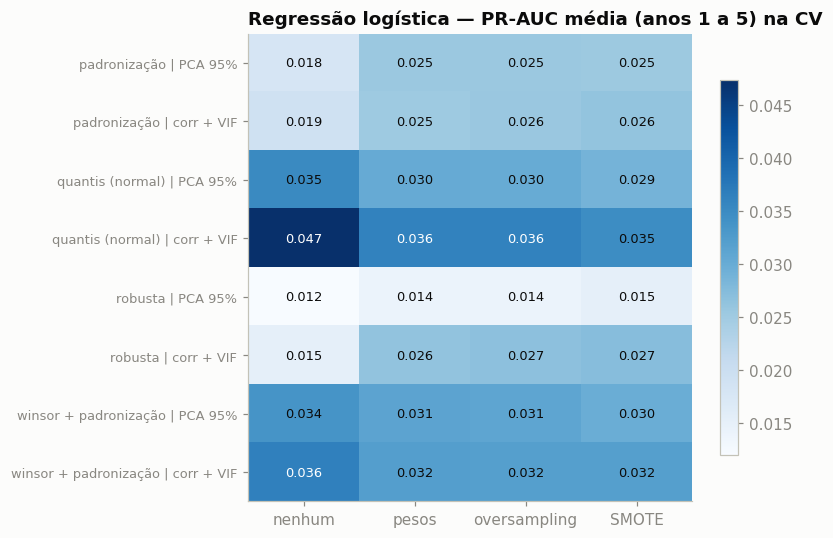

In [7]:
# PR-AUC média na CV para cada combinação
tabela_fat = fatorial.pivot_table(index=['escala', 'seleção'], columns='balanço', values='PR-AUC média')
tabela_fat = tabela_fat.reindex(columns=[b for b in BALANCOS if b in tabela_fat.columns])
fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(tabela_fat.values, cmap='Blues', aspect='auto')
for (i, j), v in np.ndenumerate(tabela_fat.values):
    if np.isfinite(v):
        ax.text(j, i, f'{v:.3f}', ha='center', va='center', fontsize=8.5,
                color='white' if v > np.nanmean(tabela_fat.values) + np.nanstd(tabela_fat.values) else TINTA)
ax.set_xticks(range(tabela_fat.shape[1]), tabela_fat.columns)
ax.set_yticks(range(tabela_fat.shape[0]), [f'{e} | {s}' for e, s in tabela_fat.index], fontsize=8.5)
ax.grid(False)
ax.set_title('Regressão logística — PR-AUC média (anos 1 a 5) na CV')
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()

In [8]:
# Efeitos principais: média da PR-AUC em cada nível de cada fator (sobre os níveis dos outros fatores)
efeitos = pd.concat({f: fatorial.groupby(f)['PR-AUC média'].agg(['mean', 'max']) for f in ['escala', 'seleção', 'balanço']})
efeitos.columns = ['PR-AUC média (média sobre os outros fatores)', 'melhor combinação com este nível']
efeitos.round(4)

PR-AUC média (média sobre os outros fatores)  melhor combinação com este nível
escala  padronização                                                 0.0238                            0.0262
        quantis (normal)                                             0.0348                            0.0473
        robusta                                                      0.0189                            0.0272
        winsor + padronização                                        0.0322                            0.0364
seleção PCA 95%                                                      0.0250                            0.0351
        corr + VIF                                                   0.0299                            0.0473
balanço SMOTE                                                        0.0274                            0.0347
        nenhum                                                       0.0271                            0.0473
        oversampling                                                 0.0276                            0.0360
        pesos                                                        0.0276                            0.0360

In [9]:
# Dimensão depois da escala + redução (ajustado em todo o treino)
dims = {}
for e in ESCALAS:
    for s in SELECOES:
        p = so_preparo(pipeline_sklearn(e, s, 'nenhum', logistica('nenhum'))).fit(X_tr, y_tr)
        dims[(e, s)] = p.transform(X_tr.head(5)).shape[1]
pd.Series(dims).unstack().reindex(index=ESCALAS, columns=SELECOES).rename_axis('escala').add_prefix('colunas: ')

,colunas: corr + VIF,colunas: PCA 95%
escala,,
padronização,30,26
robusta,30,1
winsor + padronização,32,27
quantis (normal),25,22


## 3. Regressão logística: busca de hiperparâmetros

Com o melhor pré-processamento fixo, sorteamos a força da regularização $C$ (escala log) e o tipo de penalidade
(L2 com `lbfgs`; L1 com `saga`, que zera coeficientes e faz seleção). Mesmo critério: PR-AUC média na CV.

In [10]:
ESC_LR, SEL_LR, BAL_LR = fatorial.loc[0, ['escala', 'seleção', 'balanço']]
print(f'melhor pré-processamento: escala = {ESC_LR} | redução = {SEL_LR} | balanço = {BAL_LR}')
espaco_lr = {'C': loguniform(1e-4, 1e2), 'penalty': ['l2', 'l2', 'l1']}
busca_lr = []
t0 = time.time()
for i, prm in enumerate(ParameterSampler(espaco_lr, n_iter=3 if RAPIDO else 15, random_state=SEMENTE)):
    t1 = time.time()
    extra = dict(C=prm['C'], penalty=prm['penalty'])
    if prm['penalty'] == 'l1':
        extra.update(solver='saga', tol=1e-3)
    P = oof(lambda: pipeline_sklearn(ESC_LR, SEL_LR, BAL_LR, logistica(BAL_LR, **extra)), BAL_LR, X_tr, y_tr, DIV)
    media, dp = metricas_cv(y_tr, P, DIV)
    busca_lr.append({**prm, 'PR-AUC média': media['PR-AUC média'], 'dp': dp['PR-AUC média'],
                     'ROC-AUC média': media['ROC-AUC média'], 'Log loss': media['Log loss (multiclasse)'], 'P': P})
    print(f'{i + 1:2d}: C = {prm["C"]:.4g}, {prm["penalty"]}: PR-AUC média = {media["PR-AUC média"]:.4f} ({time.time() - t1:.0f}s)')
TEMPO['Logística: busca de hiperparâmetros'] = time.time() - t0
busca_lr = pd.DataFrame(busca_lr).sort_values('PR-AUC média', ascending=False).reset_index(drop=True)
# referência: C = 1, L2 (o mesmo do fatorial)
ref = fatorial.loc[0, 'PR-AUC média']
print(f'C = 1, L2 (fatorial): {ref:.4f}')
busca_lr.drop(columns='P').round(4)

melhor pré-processamento: escala = quantis (normal) | redução = corr + VIF | balanço = nenhum


 1: C = 0.01767, l2: PR-AUC média = 0.0477 (3s)


 2: C = 0.001261, l2: PR-AUC média = 0.0401 (3s)


 3: C = 0.3812, l2: PR-AUC média = 0.0473 (3s)


 4: C = 0.0008629, l1: PR-AUC média = 0.0097 (3s)


 5: C = 0.05695, l2: PR-AUC média = 0.0478 (3s)


... (7 outputs left out)

13: C = 0.02507, l1: PR-AUC média = 0.0494 (4s)


14: C = 0.0545, l1: PR-AUC média = 0.0504 (4s)


15: C = 0.5132, l1: PR-AUC média = 0.0482 (4s)
C = 1, L2 (fatorial): 0.0473


,C,penalty,PR-AUC média,dp,ROC-AUC média,Log loss
0,0.0545,l1,0.0504,0.0089,0.7584,0.2451
1,0.0251,l1,0.0494,0.0080,0.7512,0.2465
2,0.4043,l1,0.0485,0.0076,0.7593,0.2451
3,0.5132,l1,0.0482,0.0076,0.7589,0.2452
4,0.0569,l2,0.0478,0.0077,0.7583,0.2453
5,0.0177,l2,0.0477,0.0088,0.7592,0.2452
6,2.1478,l2,0.0473,0.0073,0.7570,0.2456
7,0.1408,l2,0.0473,0.0074,0.7577,0.2455
8,0.5069,l2,0.0473,0.0072,0.7572,0.2456
9,0.3812,l2,0.0473,0.0073,0.7572,0.2456


In [11]:
# Melhor da busca (1 divisão da CV); a escolha final sai da seleção robusta (seção 4)
if busca_lr.loc[0, 'PR-AUC média'] > ref:
    print('melhor da busca:', {'C': float(busca_lr.loc[0, 'C']), 'penalty': busca_lr.loc[0, 'penalty']})
else:
    print('a busca não superou C = 1, L2')

melhor da busca: {'C': 0.054502936945582565, 'penalty': 'l1'}


## 4. Seleção robusta: CV repetida e testes pareados

Até aqui cada configuração foi avaliada em **uma** divisão de 5 folds. Diferenças pequenas entre as melhores podem
ser só efeito dessa divisão. Para escolher o modelo final:

1. **Candidatos**: as 3 melhores configurações distintas do fatorial (C = 1, L2) e da busca de $C$ e penalidade.
2. **CV repetida 3 × 5**: a mesma CV de 5 folds em 3 divisões diferentes do treino (15 folds). A escolha final é a
   maior PR-AUC média nesses 15 folds.
3. **Testes pareados contra o vencedor** (correção de Holm):
   - **t corrigido de Nadeau e Bengio** sobre as 15 diferenças por fold (a variância é inflada por
     $1/J + n_\text{val}/n_\text{treino}$, porque os treinos dos folds se sobrepõem);
   - ***bootstrap* pareado por empresa** (1.000 reamostras estratificadas do treino, as mesmas para os dois modelos)
     da PR-AUC média calculada nas previsões fora da amostra de cada repetição.

In [12]:
def config_lr(e, s, b, C, pen):
    return {'escala': e, 'seleção': s, 'balanço': b, 'C': float(C), 'penalty': pen}


def nome_lr(c):
    return f"{c['escala']} | {c['seleção']} | {c['balanço']} | C = {c['C']:.3g}, {c['penalty'].upper()}"


def fazer_lr(c):
    extra = dict(C=c['C'], penalty=c['penalty'], **({'solver': 'saga', 'tol': 1e-3} if c['penalty'] == 'l1' else {}))
    return lambda: pipeline_sklearn(c['escala'], c['seleção'], c['balanço'], logistica(c['balanço'], **extra))


pool = [(config_lr(r['escala'], r['seleção'], r['balanço'], 1.0, 'l2'), r['PR-AUC média'],
         OOF_LR[(r['escala'], r['seleção'], r['balanço'])]) for _, r in fatorial.iterrows()]
pool += [(config_lr(ESC_LR, SEL_LR, BAL_LR, r['C'], r['penalty']), r['PR-AUC média'], r['P']) for _, r in busca_lr.iterrows()]
pool.sort(key=lambda t: -t[1])
CANDIDATOS_LR = {}
for c, pr, P in pool:
    if nome_lr(c) not in CANDIDATOS_LR:
        CANDIDATOS_LR[nome_lr(c)] = (c, pr, P)
    if len(CANDIDATOS_LR) == 3:
        break

DIVS = {r: (DIV if r == 0 else folds(y_tr, N_FOLDS, r)) for r in range(REPETICOES)}
PM_LR = {}
t0 = time.time()
for nome, (c, pr, P0) in CANDIDATOS_LR.items():
    PM_LR[nome] = [P0] + [oof(fazer_lr(c), c['balanço'], X_tr, y_tr, DIVS[r]) for r in range(1, REPETICOES)]
    print(f'{nome}: {REPETICOES} repetições | {time.time() - t0:.0f}s')
TEMPO['Logística: seleção robusta (CV repetida)'] = time.time() - t0


def por_fold(nome, met='PR-AUC média'):
    return np.array([metricas(y_tr[iva], PM_LR[nome][r][iva])[met] for r in range(REPETICOES) for _, iva in DIVS[r]])


FOLDS_PR = {n: por_fold(n) for n in PM_LR}
robusta_lr = pd.DataFrame({n: {
    'PR-AUC média (divisão principal)': CANDIDATOS_LR[n][1],
    f'PR-AUC média ({REPETICOES}×{N_FOLDS} folds)': FOLDS_PR[n].mean(),
    'dp entre os folds': FOLDS_PR[n].std(ddof=1),
    f'PR-AUC faliu ({REPETICOES}×{N_FOLDS} folds)': por_fold(n, 'PR-AUC faliu').mean()} for n in PM_LR}).T
robusta_lr = robusta_lr.sort_values(robusta_lr.columns[1], ascending=False)
VENCEDOR_LR = robusta_lr.index[0]
print('vencedor:', VENCEDOR_LR)
robusta_lr.round(4)

quantis (normal) | corr + VIF | nenhum | C = 0.0545, L1: 3 repetições | 8s


quantis (normal) | corr + VIF | nenhum | C = 0.0251, L1: 3 repetições | 15s


quantis (normal) | corr + VIF | nenhum | C = 0.404, L1: 3 repetições | 23s


vencedor: quantis (normal) | corr + VIF | nenhum | C = 0.0545, L1


,PR-AUC média (divisão principal),PR-AUC média (3×5 folds),dp entre os folds,PR-AUC faliu (3×5 folds)
"quantis (normal) | corr + VIF | nenhum | C = 0.0545, L1",0.0504,0.0501,0.0062,0.1962
"quantis (normal) | corr + VIF | nenhum | C = 0.0251, L1",0.0494,0.0490,0.0052,0.1931
"quantis (normal) | corr + VIF | nenhum | C = 0.404, L1",0.0485,0.0485,0.0072,0.2001


In [13]:
def pr_media_reps(y, Pr):
    """PR-AUC média dos anos 1 a 5 em cada repetição (Pr: empresas × repetições × classes), promediada."""
    return np.mean([np.mean([average_precision_score((y == h).astype(int), Pr[:, r, h]) for h in HORIZONTES])
                    for r in range(Pr.shape[1])])


AMOSTRAS = amostras_bootstrap(y_tr, 100 if RAPIDO else 1000, semente=SEMENTE)
PR_V = np.stack(PM_LR[VENCEDOR_LR], axis=1)
linhas = []
for n in PM_LR:
    if n == VENCEDOR_LR:
        continue
    dif, t, p_t, gl = t_corrigido(FOLDS_PR[VENCEDOR_LR] - FOLDS_PR[n], 1 / (N_FOLDS - 1))
    b = bootstrap_pareado(pr_media_reps, y_tr, PR_V, np.stack(PM_LR[n], axis=1), AMOSTRAS)
    linhas.append({'candidato': n, 'vencedor − candidato (média dos folds)': dif,
                   'folds em que o vencedor é melhor': f'{int((FOLDS_PR[VENCEDOR_LR] > FOLDS_PR[n]).sum())} de {len(FOLDS_PR[n])}',
                   't corrigido': t, 'p (t corrigido)': p_t, 'Δ bootstrap (OOF)': b['diferença'],
                   'IC 95% inf.': b['IC 95% inf.'], 'IC 95% sup.': b['IC 95% sup.'], 'p (bootstrap)': b['p (bootstrap)']})
testes_lr = pd.DataFrame(linhas).set_index('candidato')
if len(testes_lr):
    testes_lr['p Holm (t corrigido)'] = holm(testes_lr['p (t corrigido)'])
    testes_lr['p Holm (bootstrap)'] = holm(testes_lr['p (bootstrap)'])
    testes_lr['diferença significativa (5%)?'] = np.where(
        (testes_lr['p Holm (t corrigido)'] < 0.05) & (testes_lr['p Holm (bootstrap)'] < 0.05), 'sim', 'não')

C_FINAL = CANDIDATOS_LR[VENCEDOR_LR][0]
ESC_LR, SEL_LR, BAL_LR = C_FINAL['escala'], C_FINAL['seleção'], C_FINAL['balanço']
PRM_LR = {'C': C_FINAL['C'], 'penalty': C_FINAL['penalty']}
extra_lr = dict(PRM_LR, **({'solver': 'saga', 'tol': 1e-3} if PRM_LR['penalty'] == 'l1' else {}))
OOF_LR_FINAL = PM_LR[VENCEDOR_LR][0]
print('regressão logística final:', C_FINAL)
testes_lr.round(4)

regressão logística final: {'escala': 'quantis (normal)', 'seleção': 'corr + VIF', 'balanço': 'nenhum', 'C': 0.054502936945582565, 'penalty': 'l1'}


,vencedor − candidato (média dos folds),folds em que o vencedor é melhor,t corrigido,p (t corrigido),Δ bootstrap (OOF),IC 95% inf.,IC 95% sup.,p (bootstrap),p Holm (t corrigido),p Holm (bootstrap),diferença significativa (5%)?
candidato,,,,,,,,,,,
"quantis (normal) | corr + VIF | nenhum | C = 0.0251, L1",0.0011,10 de 15,0.8774,0.3951,0.0008,-0.0007,0.0024,0.342,0.5875,0.488,não
"quantis (normal) | corr + VIF | nenhum | C = 0.404, L1",0.0017,12 de 15,1.0909,0.2937,0.0011,-0.0008,0.0030,0.244,0.5875,0.488,não


## 5. Modelo final (todo o treino) e tabela treino / validação / teste

O modelo escolhido é reajustado nos 80% de treino. *Treino* = métricas dentro da amostra; *validação* = média
dos 5 folds da CV (previsões fora da amostra); *teste* = 20% separados no início. A comparação completa com a MLP,
com intervalos de confiança e testes, está no notebook 05.

In [14]:
pi_tr = priors(y_tr)
linhas = []
t0 = time.time()
m_lr = pipeline_sklearn(ESC_LR, SEL_LR, BAL_LR, logistica(BAL_LR, **extra_lr)).fit(X_tr, y_tr)
TEMPO['Regressão logística: ajuste final'] = time.time() - t0
P_tr = corrigir_priors(m_lr.predict_proba(X_tr), pi_tr, BAL_LR)
P_te = corrigir_priors(m_lr.predict_proba(X_te), pi_tr, BAL_LR)
salvar_previsoes('logistica', P_oof=OOF_LR_FINAL, P_tr=P_tr, P_te=P_te)
salvar_previsoes('logistica_rep', P_oof=np.stack(PM_LR[VENCEDOR_LR]))  # repetições × empresas × classes
media, _ = metricas_cv(y_tr, OOF_LR_FINAL, DIV)
for conj, met in [('treino', metricas(y_tr, P_tr)), ('validação (CV)', media), ('teste', metricas(y_te, P_te))]:
    linhas.append({'modelo': 'Regressão logística', 'conjunto': conj, **{k: met[k] for k in
                   ['PR-AUC média', 'ROC-AUC média', 'Recall@FPR5% médio', 'PR-AUC faliu', 'Log loss (multiclasse)',
                    'Brier (multiclasse)', 'PR-AUC ano 1', 'PR-AUC ano 5']}})
salvar_previsoes('y', y_tr=y_tr, y_te=y_te, arquivo_tr=tr['arquivo'].values, arquivo_te=te['arquivo'].values)
tvt = pd.DataFrame(linhas).set_index(['modelo', 'conjunto'])
tvt.round(4)

PR-AUC média  ROC-AUC média  Recall@FPR5% médio  PR-AUC faliu  Log loss (multiclasse)  Brier (multiclasse)  PR-AUC ano 1  PR-AUC ano 5
modelo              conjunto                                                                                                                                              
Regressão logística treino                0.0490         0.7690              0.2817        0.1993                  0.2427               0.0895        0.0921        0.0227
                    validação (CV)        0.0504         0.7584              0.2541        0.1962                  0.2451               0.0898        0.0942        0.0236
                    teste                 0.0518         0.7648              0.2724        0.2080                  0.2429               0.0894        0.1033        0.0354

In [15]:
# Coeficientes da regressão logística final (só faz sentido sem PCA): maiores |coeficientes| da classe 1 (falência no 1º ano)
if SEL_LR != 'PCA 95%':
    nomes = so_preparo(m_lr).transform(X_tr.head(2)).columns
    coef = pd.DataFrame(m_lr.named_steps['modelo'].coef_.T, index=nomes, columns=[NOME_CLASSE[k] for k in CLASSES])
    display(coef.loc[coef.iloc[:, 1].abs().sort_values(ascending=False).index[:12]].round(3))
else:
    print('modelo final usa PCA: coeficientes estão no espaço das componentes')

,não faliu,faliu no ano 1,faliu no ano 2,faliu no ano 3,faliu no ano 4,faliu no ano 5
X45,0.012,-0.287,0.000,-0.013,0.029,0.000
X24,0.156,0.265,0.000,0.000,0.000,-0.062
X6,-0.024,-0.164,0.000,0.000,0.097,0.043
X41,0.146,-0.158,-0.106,0.000,0.000,0.000
X39,0.496,-0.142,-0.111,-0.051,0.009,0.072
X21,0.000,-0.106,0.000,-0.102,0.000,0.073
X15,-0.062,-0.073,0.000,0.000,0.017,0.056
X40,0.203,-0.071,-0.039,0.000,0.000,0.000
X34,-0.110,0.069,0.000,0.000,0.000,-0.021
X63,0.002,-0.065,-0.014,0.000,0.000,0.000


## 6. Salvando

In [16]:
fatorial.to_csv('resultados/fatorial_logistica.csv', encoding='utf-8-sig', index=False)
busca_lr.drop(columns='P').to_csv('resultados/busca_logistica.csv', encoding='utf-8-sig', index=False)
robusta_lr.to_csv('resultados/logistica_selecao_robusta.csv', encoding='utf-8-sig')
testes_lr.to_csv('resultados/logistica_testes_selecao.csv', encoding='utf-8-sig')
tvt.to_csv('resultados/treino_validacao_teste_03.csv', encoding='utf-8-sig')
salvar_json('config_03', {
    'Regressão logística': {'escala': ESC_LR, 'seleção': SEL_LR, 'balanço': BAL_LR, **PRM_LR},
    'candidatos': list(PM_LR),
    'tempo_s': TEMPO,
})
print({k: f'{v / 60:.1f} min' for k, v in TEMPO.items()})

{'Logística: fatorial de pré-processamento': '14.1 min', 'Logística: busca de hiperparâmetros': '0.9 min', 'Logística: seleção robusta (CV repetida)': '0.4 min', 'Regressão logística: ajuste final': '0.0 min'}


## Conclusões

- **Pré-processamento (fatorial de 32 combinações):** a transformação por **quantis para a normal** com o filtro
  **correlação + VIF** e **sem reamostragem** foi a melhor combinação (PR-AUC média dos anos 1–5 = 0,047 na CV).
  Reamostrar piorou: pesos de classe e oversampling ficaram em 0,036 e SMOTE em 0,035, mesmo com a correção de
  *priors*. O PCA 95% (0,035) perdeu para o corte por correlação + VIF, que mantém 24–25 dos 63 indicadores em cada
  fold (31–32 saem por correlação e 7 pelo VIF).
- **Hiperparâmetros:** a busca escolheu **L1 com C = 0,0545**. Com C muito pequeno (< 0,001) a L1 zera todos os
  coeficientes e o modelo vira a prevalência (ROC-AUC = 0,5).
- **Seleção robusta:** os três melhores candidatos (L1 com C = 0,0545, 0,0251 e 0,404) ficaram a 0,001–0,002 um do
  outro na CV repetida 3 × 5. Nenhuma diferença é significativa (t corrigido e *bootstrap*, p de Holm ≥ 0,49): a
  escolha dentro dessa faixa de C praticamente não importa.
- **Desempenho:** PR-AUC média por ano 0,050 na validação e 0,052 no teste; PR-AUC de "faliu" 0,196 e 0,208
  (prevalência 0,048); ROC-AUC média 0,76. Treino, validação e teste ficam próximos: a logística não sobreajusta, o
  limite dela é de capacidade (fronteira linear nas variáveis transformadas).
- **Custo:** cerca de 15 min de CPU no total, quase todo no fatorial de pré-processamento.